# 07 · Understanding the results

The comparison table says *what* each model scored. This notebook asks *why*, using only the saved results in `results/`. It needs no GPU and no model, only Stockfish (for one baseline, about 2 minutes).

Every model graded on the test set is included automatically, so rerun it after a new run (e.g. RL) is pushed. The "What it shows" notes were written for base, SFT, and DPO.

1. How sure are we? (intervals and paired comparisons)
2. What does guessing score? (a random-move baseline)
3. What kind of illegal moves?
4. How good are the legal moves?
5. Fewer blunders, or better tactics?
6. What SFT learned
7. What DPO did
8. RL
9. Summary

**Figures** (in `results/figures/`): `accuracy_intervals.png`, `accuracy_decomposition.png`, `illegal_reasons.png`, `move_quality.png`, `sft_token_probability.png`, `dpo_diagnostics.png`.

In [1]:
# Settings
RANDOM_MOVES_PER_PUZZLE = 3   # random legal moves scored by Stockfish per puzzle, for the baseline in section 4

import json
import math

import chess
import pandas as pd

from chesslm import plots
from chesslm.analysis import chance_correct, illegal_reason, random_move_losses, sign_test, wilson_interval
from chesslm.config import REPO_ROOT, load_config
from chesslm.engine import MoveScorer

RESULTS = REPO_ROOT / "results"
FIGURES = RESULTS / "figures"
puzzles = pd.read_csv(REPO_ROOT / "data" / "eval" / "puzzles_test.csv").set_index("puzzle_id")
summary = pd.read_csv(RESULTS / "summary.csv")

runs = [run for run in summary.run if not run.endswith("_dev")]  # every model graded on the test set
graded = {run: pd.DataFrame(json.load(open(RESULTS / f"{run}.json"))["rows"]).set_index("puzzle_id").loc[puzzles.index]
          for run in runs}
N = len(puzzles)
print(f"Models: {', '.join(runs)}  ({N:,} test puzzles each)")

W1103 00:25:36.299000 26525 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Models: base, sft_v1, dpo_v1  (1,000 test puzzles each)


## 1. How sure are we?

Each accuracy is measured on 1,000 puzzles, so it carries sampling noise: another 1,000 puzzles of the same kind would give a slightly different number. The **95% interval** is the range of true accuracies that are consistent with what we observed (a Wilson interval, which behaves well for small percentages).

In [2]:
table = pd.DataFrame({run: {"solved": g.correct.sum(), "accuracy": g.correct.mean(),
                             "legal_rate": (g.outcome == "legal").mean()} for run, g in graded.items()}).T
table["low"], table["high"] = zip(*[wilson_interval(k, N) for k in table.solved])
table["accuracy_when_legal"] = table.accuracy / table.legal_rate

print("Puzzle accuracy with 95% intervals:")
for run, row in table.iterrows():
    print(f"  {run:8s} {row.accuracy:6.1%}   ({row.low:.1%} to {row.high:.1%})")

Puzzle accuracy with 95% intervals:
  base       2.8%   (1.9% to 4.0%)
  sft_v1     7.8%   (6.3% to 9.6%)
  dpo_v1     5.9%   (4.6% to 7.5%)


### Paired comparisons

Overlapping intervals do not settle whether two models differ, because both models answered the *same* puzzles. A paired comparison uses that: count the puzzles that only one of the two models solves. If the models were equally good, each such puzzle would be equally likely to be solved by either one. The **p-value** is the probability of a split at least as uneven as the observed one under that assumption. Below 0.05 is the usual threshold for calling a difference real. (This is the sign test, also called McNemar's exact test.)

Each trained model is compared with the model it started from.

In [3]:
comparisons = [("base", "sft_v1")] + [("sft_v1", run) for run in runs if run not in ("base", "sft_v1")]
rows = []
for old, new in comparisons:
    a, b = graded[old].correct, graded[new].correct
    gained, lost = int((~a & b).sum()), int((a & ~b).sum())
    rows.append({"comparison": f"{old} -> {new}", "solved by both": int((a & b).sum()),
                 "only the new model": gained, "only the old model": lost,
                 "net change": gained - lost, "p-value": round(sign_test(gained, lost), 4)})
pd.DataFrame(rows).set_index("comparison")

,solved by both,only the new model,only the old model,net change,p-value
comparison,,,,,
base -> sft_v1,7,71,21,50,0.0000
sft_v1 -> dpo_v1,37,22,41,-19,0.0226


**What it shows**
- SFT solves 71 puzzles that the base model misses, and misses 21 that it solves (p < 0.0001). The improvement is real.
- DPO solves 22 puzzles that SFT misses, and misses 41 that SFT solves (p ≈ 0.02). The drop is unlikely to be noise. It comes from a single run with one set of settings, though (section 7).

## 2. What does guessing score?

A useful reference point is a player who picks one of the legal moves uniformly at random. In each puzzle, this solves it with probability (number of correct moves) / (number of legal moves), usually 1/34. Averaging over the puzzles gives the exact expected accuracy, with no simulation needed.

Accuracy also splits into two factors:

**accuracy = (share of answers that are legal) × (accuracy when the answer is legal)**

The first factor measures whether the model produces a valid move at all. The second measures how well it chooses among valid moves, and only this one is comparable with the random-move line.

A random legal move solves 5.6% of the puzzles on average (a puzzle has 34 legal moves, median).



,legal_rate,accuracy_when_legal
base,41.2%,6.8%
sft_v1,72.2%,10.8%
dpo_v1,63.3%,9.3%


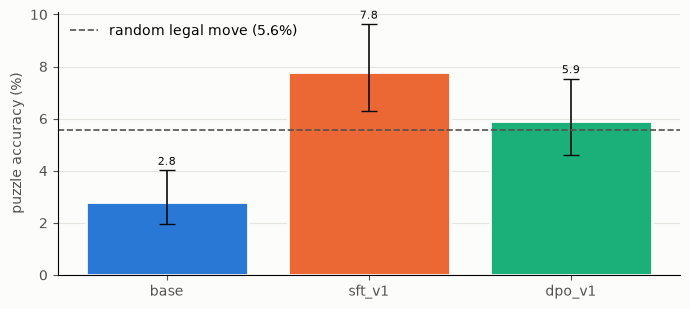

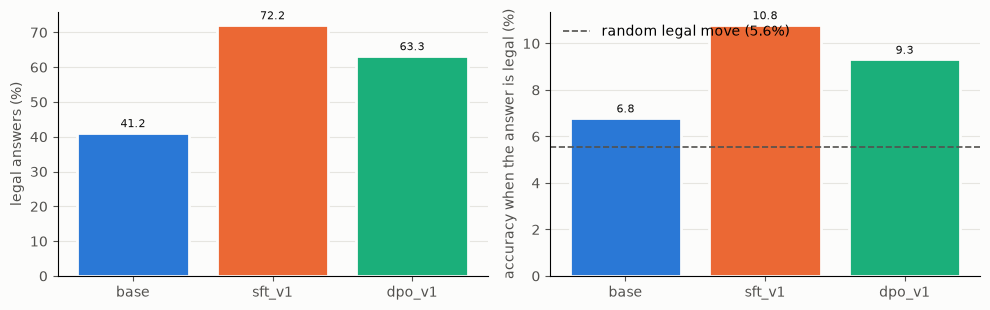

In [4]:
chance = puzzles.apply(chance_correct, axis=1)
CHANCE = chance.mean()
n_legal = puzzles.fen.map(lambda fen: chess.Board(fen).legal_moves.count())
print(f"A random legal move solves {CHANCE:.1%} of the puzzles on average "
      f"(a puzzle has {n_legal.median():.0f} legal moves, median).\n")

plots.accuracy_with_intervals(table, CHANCE, FIGURES / "accuracy_intervals.png")
plots.accuracy_decomposition(table, CHANCE, FIGURES / "accuracy_decomposition.png")
table[["legal_rate", "accuracy_when_legal"]].map("{:.1%}".format)

**What it shows**
- A random legal move scores 5.6%. That is higher than the base model (2.8%) and about equal to DPO (5.9%). SFT (7.8%) is above it, and its interval (6.3% to 9.6%) excludes it.
- The base model's legal answers are about as good as random (6.8% vs. 5.6%). Its low score comes mostly from answers that are not legal moves.
- SFT improves both factors: legal answers rise from 41% to 72%, and accuracy on legal answers from 6.8% to 10.8%, about twice the random rate. So SFT taught more than the answer format: it also picks better moves than chance.
- DPO lowers both factors compared with SFT (72% to 63% legal, 10.8% to 9.3% when legal).
- Caveat: "accuracy when legal" is measured on the puzzles where each model happened to answer legally, which are not the same puzzles for every model.

### By rating band

In [5]:
bands = pd.DataFrame({run: g.groupby(puzzles.band).correct.mean() for run, g in graded.items()})
bands["random legal move"] = chance.groupby(puzzles.band).mean()
low, high = wilson_interval(20, 250)
print(f"With 250 puzzles per band, an accuracy near 8% has a 95% interval of about ±{(high - low) / 2:.1%}.\n")
(bands.loc[plots.BANDS] * 100).round(1)

With 250 puzzles per band, an accuracy near 8% has a 95% interval of about ±3.4%.



,base,sft_v1,dpo_v1,random legal move
band,,,,
<1200,2.4,8.4,5.2,4.4
1200-1800,4.8,8.4,6.0,4.6
1800-2400,2.4,10.8,8.0,5.8
2400+,1.6,3.6,4.4,7.4


**What it shows**
- With 250 puzzles per band, each number is uncertain by about ±3.4 points, so most differences between bands are within noise. Per-band results should not be over-interpreted.
- In the 2400+ band, random guessing (7.4%) beats every model. These puzzles more often leave only a few legal moves (section 3 explains why that hurts the models), which makes guessing easier.

## 3. What kind of illegal moves?

An illegal answer names a move that is not allowed in the position. Checking the board tells us why:
- **no own piece there:** the starting square is empty or holds an opponent's piece
- **piece can't move there:** the piece exists, but cannot reach that square (it does not move that way, or the path is blocked)
- **leaves king in check:** the move follows the piece's movement rules, but leaves the player's own king in check (moving a pinned piece, or ignoring a check)
- **ambiguous:** SAN that fits more than one piece

Answers written in UCI, as the prompt asks: base 3%, sft_v1 100%, dpo_v1 100%


,no own piece there,piece can't move there,leaves king in check,ambiguous,all illegal
base,15,379,35,29,458
sft_v1,13,172,93,0,278
dpo_v1,22,272,73,0,367


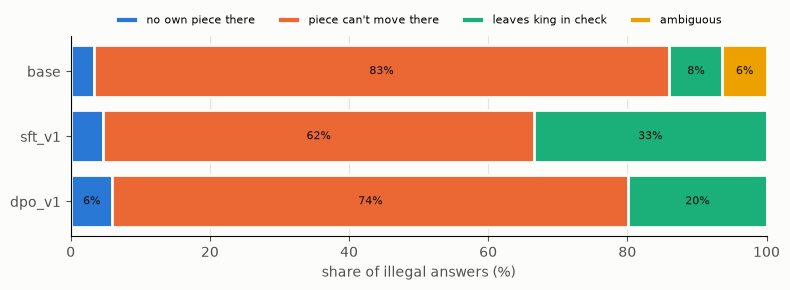

In [6]:
REASONS = ["no own piece there", "piece can't move there", "leaves king in check", "ambiguous"]
reasons = pd.DataFrame({
    run: g[g.outcome == "illegal"].apply(lambda row: illegal_reason(puzzles.fen[row.name], row.reply), axis=1)
          .value_counts().reindex(REASONS, fill_value=0)
    for run, g in graded.items()}).T
reasons["all illegal"] = reasons.sum(axis=1)

uci = {run: g.reply.str.strip().str.match(r"[a-h][1-8][a-h][1-8]").mean() for run, g in graded.items()}
print("Answers written in UCI, as the prompt asks: " + ", ".join(f"{run} {share:.0%}" for run, share in uci.items()))

shares = reasons[REASONS].div(reasons["all illegal"], axis=0) * 100
plots.stacked_shares(shares, plots.COLORS, "share of illegal answers (%)", FIGURES / "illegal_reasons.png")
reasons

Positions with only a few legal moves are where the rules bind most: usually the king is in check, or pieces are pinned. How often does each model answer legally there?

In [7]:
few = n_legal <= 10
in_check = puzzles.fen.map(lambda fen: chess.Board(fen).is_check())
print(f"{few.sum()} puzzles have 10 or fewer legal moves; in {in_check[few].mean():.0%} of them the king is in check.\n")
pd.DataFrame({run: {"legal answers, 10 or fewer legal moves": (g.outcome == "legal")[few].mean(),
                    "legal answers, more than 10": (g.outcome == "legal")[~few].mean()}
              for run, g in graded.items()}).T.map("{:.0%}".format)

124 puzzles have 10 or fewer legal moves; in 50% of them the king is in check.



,"legal answers, 10 or fewer legal moves","legal answers, more than 10"
base,19%,44%
sft_v1,29%,78%
dpo_v1,29%,68%


**What it shows**
- Only 3% of the base model's answers are in UCI, although the prompt asks for it (most are in SAN). SFT and DPO always use UCI: SFT taught the answer format.
- "No own piece there" is rare for every model (6% or less of illegal answers). The models almost always name a square holding one of their own pieces, so they read *where the pieces are* from the FEN fairly well.
- Most illegal answers move a real piece where it cannot go, and a third of SFT's illegal answers break the check rule. Both require relations between pieces (lines of movement, blocking pieces, attacks on the king), not just their positions.
- This is clearest when there are only a few legal moves: SFT answers legally only 29% of the time there, against 78% otherwise. The model does not take the constraints of the position into account.
- DPO adds about 100 more "piece can't move there" answers.

## 4. How good are the legal moves?

**Centipawn loss** measures how much worse a move is than Stockfish's best move, in hundredths of a pawn. 0 means as good as the best move. It is capped at 1000 (ten pawns, or a missed or allowed checkmate), so a single blunder does not dominate the average. **ACPL** is the average over a model's legal answers.

As a reference, Stockfish also scores a few random legal moves in every puzzle.

In [8]:
stockfish_cfg = load_config("eval")["stockfish"]
with MoveScorer(stockfish_cfg) as scorer:
    random_losses = random_move_losses(puzzles.reset_index(), scorer, RANDOM_MOVES_PER_PUZZLE, seed=42)
print(f"Scored {len(random_losses):,} random legal moves.")

Scored 2,989 random legal moves.


,0-50 (about best),51-200,201-999,1000 (cap)
base,6.8,1.2,29.4,62.6
sft_v1,10.9,0.7,29.2,59.1
dpo_v1,9.6,0.6,27.3,62.4
random legal move,5.9,1.2,32.6,60.4


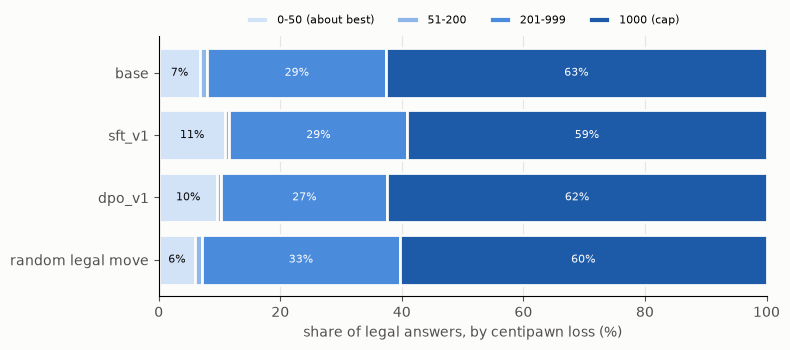

In [9]:
CAP = stockfish_cfg["cp_loss_cap"]
BINS = {"0-50 (about best)": (0, 50), "51-200": (51, 200), "201-999": (201, CAP - 1), f"{CAP} (cap)": (CAP, CAP)}

def quality_shares(losses):
    return {name: losses.between(lo, hi).mean() * 100 for name, (lo, hi) in BINS.items()}

legal_losses = {run: g.cp_loss.dropna() for run, g in graded.items()}
quality = pd.DataFrame({**{run: quality_shares(losses) for run, losses in legal_losses.items()},
                        "random legal move": quality_shares(random_losses.cp_loss)}).T
plots.stacked_shares(quality, plots.BLUES, "share of legal answers, by centipawn loss (%)", FIGURES / "move_quality.png")
quality.round(1)

ACPL only averages legal answers, and each model answers legally on different puzzles. A fairer reference is random moves on the *same* puzzles where the model's answer was legal:

In [10]:
random_by_puzzle = random_losses.groupby("puzzle_id").cp_loss.mean()
pd.DataFrame({run: {"legal answers": len(losses), "model ACPL": losses.mean(),
                    "random-move ACPL, same puzzles": random_by_puzzle.loc[losses.index].mean()}
              for run, losses in legal_losses.items()}).T.round(0)

,legal answers,model ACPL,"random-move ACPL, same puzzles"
base,412.0,828.0,858.0
sft_v1,722.0,793.0,858.0
dpo_v1,633.0,820.0,855.0


**What it shows**
- In puzzles, almost every legal move is either about the best or a large mistake: only about 1% of moves fall between 51 and 200. Even 60% of random moves hit the cap. This follows from how puzzles are chosen: one move wins, and most others lose material or allow a mate.
- So on puzzles, ACPL mostly repeats what accuracy already says. It sits near 800 for every model, against about 858 for random moves on the same puzzles. SFT (793) is better than random, but the gap is small next to the gap in accuracy.
- ACPL would be more informative on ordinary game positions, where many moves are reasonable and the differences between them are smaller.

## 5. Fewer blunders, or better tactics?

Our proposal asks whether a method helps because it makes the model **blunder less** or because it makes it **better at tactics**. We can look at both with the results we already have:
- a **blunder** here is a legal move that loses 200+ centipawns (the same threshold that defines a rejected move in DPO)
- **tactics:** Lichess tags every puzzle with its themes (fork, pin, mate in 1, ...), so accuracy per theme shows which kinds of tactics a model finds

In [11]:
BLUNDER = 200
pd.DataFrame({run: {"accuracy": g.correct.mean(),
                    "legal answers that are blunders": (g.cp_loss >= BLUNDER).sum() / (g.outcome == "legal").sum(),
                    "all answers: illegal, unparseable, or a blunder": ((g.outcome != "legal") | (g.cp_loss >= BLUNDER)).mean()}
              for run, g in graded.items()}).T.map("{:.0%}".format)

,accuracy,legal answers that are blunders,"all answers: illegal, unparseable, or a blunder"
base,3%,92%,97%
sft_v1,8%,88%,92%
dpo_v1,6%,90%,94%


In [12]:
THEMES = ["mateIn1", "mateIn2", "fork", "pin", "sacrifice", "defensiveMove", "advancedPawn"]
tags = puzzles.themes.str.split()
by_theme = {}
for theme in THEMES:
    has = tags.map(lambda t: theme in t)
    by_theme[theme] = {"puzzles": has.sum(), **{run: g.correct[has].mean() * 100 for run, g in graded.items()},
                       "random legal move": chance[has].mean() * 100}
low, high = wilson_interval(8, 100)
print(f"With about 100 puzzles per theme, an accuracy near 8% has a 95% interval of about ±{(high - low) / 2:.1%}.\n")
pd.DataFrame(by_theme).T.round(1).astype({"puzzles": int})

With about 100 puzzles per theme, an accuracy near 8% has a 95% interval of about ±5.4%.



,puzzles,base,sft_v1,dpo_v1,random legal move
mateIn1,110,0.0,6.4,1.8,3.3
mateIn2,85,3.5,7.1,3.5,3.2
fork,104,2.9,7.7,5.8,3.2
pin,77,1.3,14.3,14.3,6.0
sacrifice,81,1.2,7.4,3.7,4.4
defensiveMove,101,1.0,6.9,5.0,12.9
advancedPawn,90,3.3,5.6,6.7,8.7


**What it shows**
- On puzzles, the two questions are almost the same measurement. 88% of SFT's legal answers are blunders, and nearly all the rest are the correct answer: in a puzzle, missing the tactic usually *is* the blunder. So puzzle results alone cannot tell "fewer blunders" apart from "better tactics".
- No theme stands out clearly: with 40 to 110 puzzles per theme, the intervals (about ±5 points) are wider than the differences between themes.
- Even the simplest tactic is rare: SFT finds the mate in only about 6% of the mate-in-1 puzzles, and the base model in none of them.
- In defensive puzzles, random guessing (12.9%) beats every model. As in the hardest rating band, these puzzles often leave only a few legal moves, which is where the models most often answer illegally (section 3).
- To test the blunder hypothesis on its own, we need ordinary game positions, where most moves are reasonable and a blunder is a distinct mistake. Grading the models on held-out game positions would answer it.

## 6. What SFT learned

SFT minimizes the **cross-entropy loss**: the average of −log p over the answer tokens, where p is the probability the model gives to the move a 2000+ player actually played. Turned around, **exp(−loss)** is the average probability per answer token (a geometric mean). The answer tokens include an end-of-answer marker, which is easy to predict, so the move itself is somewhat less certain than this number suggests.

first training steps     loss 1.981  ->  probability per answer token 14%
first validation check   loss 0.889  ->  probability per answer token 41%
end of training          loss 0.667  ->  probability per answer token 51%

Training used 20,000 examples and 6.603 GPU-hours.


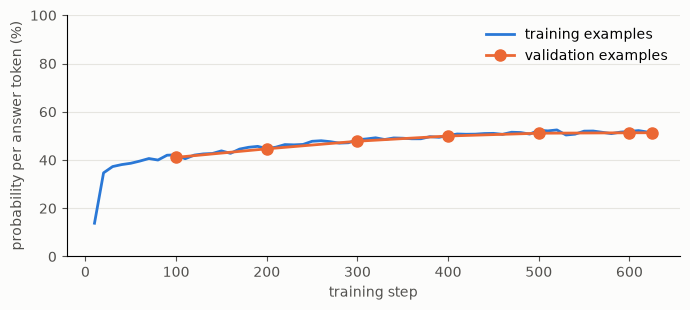

In [13]:
sft_run = json.load(open(RESULTS / "sft_v1_training.json"))
sft_log = pd.DataFrame(sft_run["log"])
first_train, val = sft_log.loss.dropna().iloc[0], sft_log.eval_loss.dropna()
for name, loss in [("first training steps", first_train), ("first validation check", val.iloc[0]),
                   ("end of training", val.iloc[-1])]:
    print(f"{name:24s} loss {loss:.3f}  ->  probability per answer token {math.exp(-loss):.0%}")
print(f"\nTraining used {sft_run['compute']['examples_seen']:,} examples and {sft_run['compute']['gpu_hours']} GPU-hours.")
plots.token_probability_curve(sft_log, FIGURES / "sft_token_probability.png");

**What it shows**
- The probability per answer token rises from 14% at the start to 51% at the end.
- The validation curve (game positions never trained on) tracks the training curve closely. The model generalizes to new positions rather than memorizing the training examples.
- The curve is still rising slowly at the end, so more data or a second epoch may help a little.
- SFT is trained to *imitate* the moves of strong human players in ordinary games, not to solve puzzles. Human moves are often not the best move, and puzzle positions hide a tactic that ordinary positions usually do not. This is one plausible reason why a clear gain in imitation gives only a modest gain in puzzle accuracy (a hypothesis we have not tested).

## 7. What DPO did

DPO trains on pairs: for the same position, a **chosen** move (Stockfish's best) and a **rejected** move (one that loses 200+ centipawns). Each move's probability is measured *relative to the SFT model* (the reference). The loss only depends on the **gap**: how much more the model raises the chosen move than the rejected one. The setting β controls how strongly the model is held close to the SFT model.

During training, TRL logs β × log(probability now / probability under SFT) for each answer. Dividing by β and exponentiating turns this back into a ratio: 1× means unchanged, 0.1× means ten times less likely than under SFT.
- **left:** how often the gap favors the chosen move (50% = no preference)
- **right:** the chosen and rejected moves' probability, relative to the SFT model (log scale)

Held-out pairs, end of training (beta = 0.1):
  prefers the chosen move:              63%
  chosen move, probability vs. SFT:     x0.049
  rejected move, probability vs. SFT:   x0.002


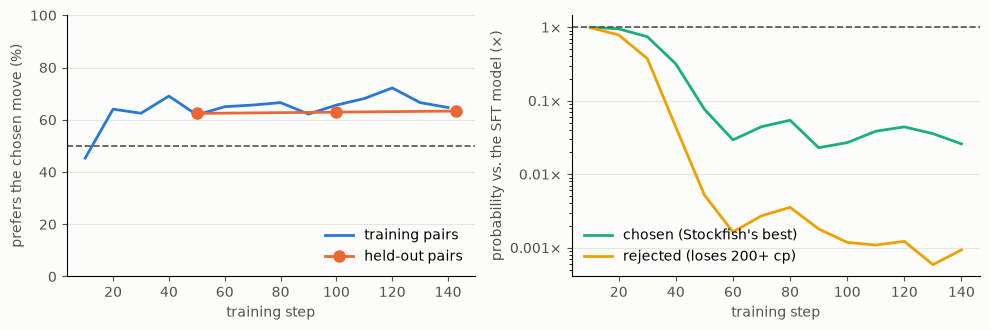

In [14]:
dpo_run = json.load(open(RESULTS / "dpo_v1_training.json"))
dpo_log, beta = pd.DataFrame(dpo_run["log"]), dpo_run["config"]["training"]["beta"]
final = dpo_log.dropna(subset=["eval_rewards/accuracies"]).iloc[-1]
print(f"Held-out pairs, end of training (beta = {beta}):")
print(f"  prefers the chosen move:              {final['eval_rewards/accuracies']:.0%}")
print(f"  chosen move, probability vs. SFT:     x{math.exp(final['eval_rewards/chosen'] / beta):.3f}")
print(f"  rejected move, probability vs. SFT:   x{math.exp(final['eval_rewards/rejected'] / beta):.3f}")
plots.dpo_diagnostics(dpo_log, beta, FIGURES / "dpo_diagnostics.png");

How each SFT answer changed under DPO (rows: SFT's answer; columns: DPO's answer to the same puzzle):

In [15]:
def outcome(g):
    return g.outcome.where(~g.correct, "correct").replace({"legal": "legal, wrong"})

ORDER = ["correct", "legal, wrong", "illegal", "unparseable"]
pd.crosstab(outcome(graded["sft_v1"]).rename("SFT answer"), outcome(graded["dpo_v1"]).rename("DPO answer")) \
  .reindex(index=ORDER, columns=ORDER, fill_value=0)

DPO answer,correct,"legal, wrong",illegal,unparseable
SFT answer,,,,
correct,37,25,16,0
"legal, wrong",18,487,139,0
illegal,4,62,212,0
unparseable,0,0,0,0


**What it shows**
- The preference rises from 50% to about 63% on held-out pairs within the first 20 steps, then stays flat. DPO learned a preference that only partly carries over to new positions.
- **Both probabilities fall.** On held-out pairs, the chosen move ends at about 0.05× its SFT probability and the rejected move at about 0.002×. DPO widened the gap mostly by pushing *both* moves down, the rejected one much further. Its loss rewards the gap, not the chosen move's own probability, so this is allowed (and is a known behavior of DPO).
- The probability removed from both moves must go to other answers. The table is consistent with this: 139 of SFT's legal-but-wrong answers and 16 of its correct answers became illegal under DPO, while 66 changed the other way. So DPO's lower accuracy comes mostly from more illegal answers.
- Only one setting was tried (β = 0.1, learning rate 2e-5, one pass over 4,549 pairs). Settings that keep the model closer to SFT could change the outcome.

## 8. RL

GRPO's reward (notebook 04) gives −1 to every illegal or unparseable answer, so unlike DPO, it directly penalizes the failure that hurt DPO. What to look for once it has run:
- the average reward rising during training
- the legal-answer rate and the accuracy when legal (section 2), compared with SFT
- the paired comparison with SFT (section 1)

In [16]:
rl_path = RESULTS / "grpo_v1_training.json"
if rl_path.exists():
    rl_log = pd.DataFrame(json.load(open(rl_path))["log"])
    rewards = rl_log.reward.dropna()
    print(f"Average reward of sampled answers: {rewards.iloc[0]:.3f} at the start -> {rewards.iloc[-1]:.3f} at the end")
    plots.reward_curve(rl_log, FIGURES / "grpo_v1_reward.png")
else:
    print("No RL run yet: run notebook 06, then rerun this notebook.")

No RL run yet: run notebook 06, then rerun this notebook.


## 9. Summary (base, SFT, DPO)

**What works**
- SFT. It taught the answer format (unparseable answers 13% → 0%), raised the legal-answer rate (41% → 72%) and accuracy (2.8% → 7.8%, p < 0.0001), and picks the correct move about twice as often as chance when its answer is legal.

**What does not work yet**
- DPO, as first set up. It lowered accuracy to 5.9% (p ≈ 0.02), mainly through more illegal answers. During training it pushed down the probability of both the chosen and the rejected move.

**Where the models struggle**
- Legality. 28% of SFT's answers are illegal, and mostly not because it misreads where pieces are, but because it ignores how they can move, blocking pieces, pins, and checks. Positions with few legal moves are the hardest (29% legal).
- Overall strength. Every model is within a few points of a random legal move (5.6%). One-move answers with no reasoning, from a model with about 2B effective parameters, leave puzzles hard.
- ACPL says little on puzzles, because almost every move there is either about the best or a large mistake. For the same reason, puzzles cannot separate "fewer blunders" from "better tactics".

**Questions these results raise** (for the team to discuss)
- DPO: keep the model closer to SFT (a higher β or lower learning rate), or add the SFT loss to the DPO loss (TRL's `rpo_alpha`). Use illegal moves as rejected answers?
- Legality: the prompt option that lists the legal moves (`show_legal_moves` in `configs/prompt.yaml`) targets the main weakness directly.
- Grade the models on held-out game positions as well, where centipawn loss is more informative and blunders can be measured separately from tactics.
- Report the random-move baseline next to every accuracy.